# 06 · Baselines : le score à battre

**Question** : avant tout modèle, que vaut le bon sens ? Si une règle simple fait déjà très bien, un modèle devra faire **nettement** mieux pour justifier sa complexité.

ce notebook n'utilise que l'**entraînement** et la **validation**.

## Les métriques, sur un exemple

Un soir, la liste signale 10 bornes. Le lendemain, 6 bornes du parc ont un épisode, dont 4 figuraient dans la liste.
- **Précision@10** = 4 / 10 = **40 %** : parmi les bornes signalées, combien avaient vraiment un problème. C'est le **rendement des déplacements** des techniciens.
- **Rappel@10** = 4 / 6 = **67 %** : parmi les problèmes du lendemain, combien étaient dans la liste. C'est la **couverture**.
- **AUC** : qualité du classement de toutes les bornes, pas seulement des 10 premières (0,5 = hasard).
- **PR-AUC** : comme l'AUC, mais centrée sur les positifs ; plus exigeante quand la cible est rare. Le hasard y vaut le taux de base (environ 7 %).

## Les règles comparées

| Règle | Ce que fait l'exploitant |
|---|---|
| Hasard | Tire 10 bornes au sort : la référence minimale |
| Épisode aujourd'hui | Inspecte les bornes qui ont eu un problème aujourd'hui |
| Pannes sur 7 jours | Inspecte les bornes qui ont eu le plus de pannes cette semaine |
| Épisode récent | Inspecte les bornes dont le dernier problème est le plus récent |
| Taux historique | Inspecte les bornes les plus souvent en panne depuis toujours |

In [2]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from evrel.data.load import get_data_dir, load_config
from evrel.models.baselines import baseline_scores
from evrel.models.evaluate import evaluate_ranking, top_k_rows, top_k_table
from evrel.viz import INK_2, NEUTRAL, PALETTE, set_style

set_style()
feats = pd.read_parquet(get_data_dir() / "processed" / "features.parquet")
ks = tuple(load_config()["evaluation"]["top_k"])
work = feats[feats["split"].isin(["train", "valid"])].copy()      # le test reste fermé
scores = baseline_scores(work)
work = work.join(scores)
RULES = list(scores.columns)
print(f"Lignes utilisées : {len(work):,} (train et valid). Test et replay non utilisés.")

Lignes utilisées : 36,620 (train et valid). Test et replay non utilisés.


## 1. Résultats sur la validation (janvier à avril 2021)

In [3]:
def results(split):
    part = work[work["split"] == split]
    return pd.DataFrame({rule: evaluate_ranking(part, rule, ks) for rule in RULES}).T

valid = results("valid")
train = results("train")
(valid * 100).round(1).rename(columns=lambda c: c if c in ("AUC",) else f"{c} (%)").assign(
    AUC=valid["AUC"].round(3))

,précision@5 (%),rappel@5 (%),précision@10 (%),rappel@10 (%),AUC,PR-AUC (%),taux de base (%)
Hasard,5.2,5.1,5.8,11.6,0.511,6.3,6.2
Épisode aujourd'hui,20.7,20.6,14.0,27.9,0.592,10.3,6.2
Pannes sur 7 jours,20.0,19.9,17.3,34.6,0.726,14.9,6.2
Épisode récent,22.3,22.3,16.5,32.9,0.713,14.6,6.2
Taux historique,10.0,10.0,12.4,24.8,0.665,9.8,6.2


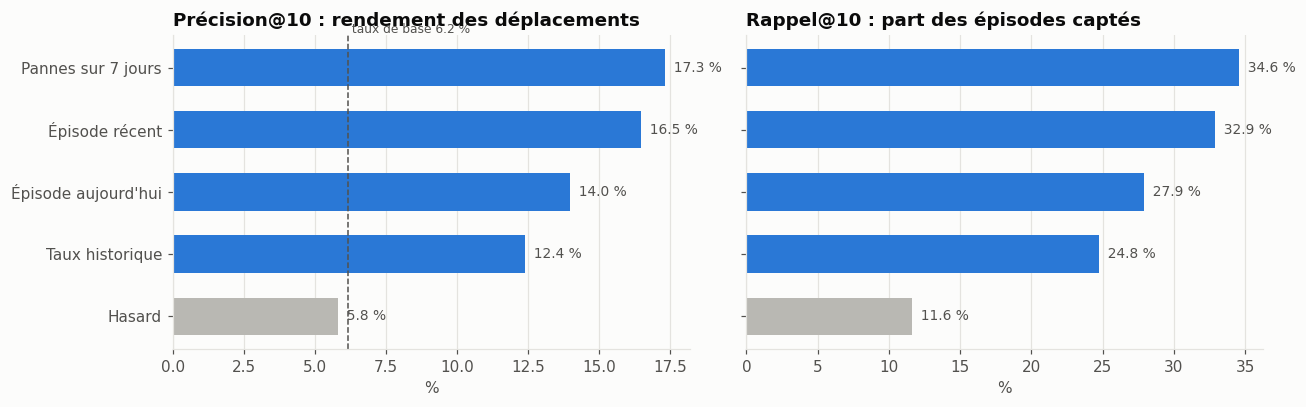

In [4]:
base = valid["taux de base"].iloc[0] * 100
order = valid.sort_values("précision@10").index

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, metric, title in [(axes[0], "précision@10", "Précision@10 : rendement des déplacements"),
                          (axes[1], "rappel@10", "Rappel@10 : part des épisodes captés")]:
    vals = valid.loc[order, metric] * 100
    colors = [NEUTRAL if r == "Hasard" else PALETTE[0] for r in order]
    ax.barh(order, vals, color=colors, height=0.6)
    for y, v in enumerate(vals):
        ax.text(v, y, f"  {v:.1f} %", va="center", fontsize=9, color=INK_2)
    ax.set_title(title)
    ax.set_xlabel("%")
    ax.grid(axis="y", visible=False)
axes[0].axvline(base, color=INK_2, lw=1, ls="--")
axes[0].text(base, len(order) - 0.45, f" taux de base {base:.1f} %", fontsize=8, color=INK_2)
plt.tight_layout()
plt.show()

**Constat** : sur 120 soirs de validation (6,2 % d'épisodes), la meilleure règle en précision@10 est « Pannes sur 7 jours » : 17,3 %, soit près de 3 fois le hasard (5,8 %), avec un rappel@10 de 34,6 % et une AUC de 0,726. « Épisode récent » suit de près (16,5 %) et est la meilleure sur les 5 premières places (22,3 %). « Épisode aujourd'hui » passe de 20,7 % au top 5 à 14,0 % au top 10 : seules une ou deux bornes sont en épisode chaque soir, le reste de sa liste est rempli au hasard.


## 2. Les résultats sont-ils stables entre l'entraînement et la validation ?


In [5]:
compare = pd.DataFrame({
    "précision@10 train (%)": (train["précision@10"] * 100).round(1),
    "précision@10 valid (%)": (valid["précision@10"] * 100).round(1),
    "AUC train": train["AUC"].round(3),
    "AUC valid": valid["AUC"].round(3),
}).loc[order[::-1]]
compare

,précision@10 train (%),précision@10 valid (%),AUC train,AUC valid
Pannes sur 7 jours,13.8,17.3,0.692,0.726
Épisode récent,17.1,16.5,0.703,0.713
Épisode aujourd'hui,14.1,14.0,0.586,0.592
Taux historique,7.7,12.4,0.595,0.665
Hasard,6.4,5.8,0.505,0.511


**Constat** : les règles se comportent de façon comparable sur l'entraînement et la validation. « Épisode récent » est très stable (17,1 % puis 16,5 %). « Pannes sur 7 jours » est meilleure en validation (17,3 % contre 13,8 %). « Taux historique » progresse nettement (7,7 % puis 12,4 %), car il s'appuie sur un historique encore court au début de 2020.

## 3. Mois par mois sur la validation

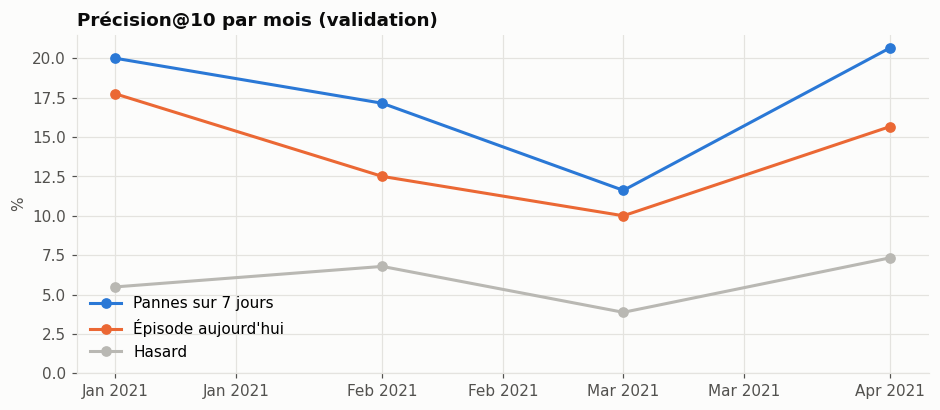

In [6]:
best = valid["précision@10"].drop("Hasard").idxmax()
part = work[work["split"] == "valid"]
fig, ax = plt.subplots()
for i, rule in enumerate(dict.fromkeys([best, "Épisode aujourd'hui", "Hasard"])):   # sans doublon
    t = top_k_table(part, rule, 10)
    m = t.groupby(t.index.to_period("M")).sum()
    ax.plot(m.index.to_timestamp(), m["épisodes_signalés"] / m["signalées"] * 100, marker="o",
            color=NEUTRAL if rule == "Hasard" else PALETTE[i], label=rule)
ax.set_title("Précision@10 par mois (validation)")
ax.set_ylabel("%")
ax.set_ylim(bottom=0)
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()

**Constat** : « Pannes sur 7 jours » reste au-dessus d'« Épisode aujourd'hui » et du hasard chaque mois, de 11,6 % en mars à 20,6 % en avril. Le creux de mars touche toutes les règles : la période est plus difficile, ce n'est pas une règle qui décroche.

## 4. La meilleure règle signale-t-elle toujours les mêmes bornes ?

Une liste qui contient chaque soir les mêmes bornes n'apprend rien de nouveau à l'exploitant, même si sa précision est bonne.

Règle « Pannes sur 7 jours » sur 120 soirs de validation :
- 45 bornes différentes apparaissent au moins une fois dans la liste
- les 10 bornes les plus fréquentes occupent 62 % des places


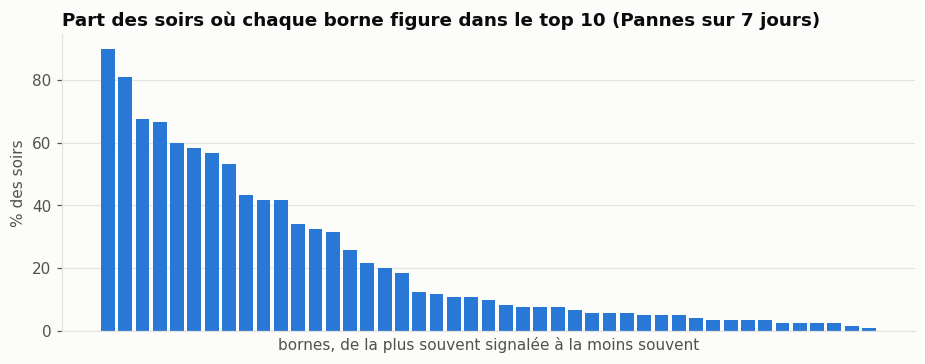

In [7]:
top = top_k_rows(part, best, 10)
freq = top["post_id"].value_counts()
n_days = part["target_date"].nunique()
print(f"Règle « {best} » sur {n_days} soirs de validation :")
print(f"- {freq.size} bornes différentes apparaissent au moins une fois dans la liste")
print(f"- les 10 bornes les plus fréquentes occupent {freq.head(10).sum() / freq.sum() * 100:.0f} % des places")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(range(len(freq)), freq.values / n_days * 100, color=PALETTE[0], width=0.8)
ax.set_title(f"Part des soirs où chaque borne figure dans le top 10 ({best})")
ax.set_ylabel("% des soirs")
ax.set_xlabel("bornes, de la plus souvent signalée à la moins souvent")
ax.set_xticks([])
plt.show()

**Constat** : la liste de « Pannes sur 7 jours » est très répétitive : sur 120 soirs, seules 45 bornes différentes y apparaissent, les 10 plus fréquentes occupent 62 % des places, et une borne figure dans la liste 9 soirs sur 10.


## 5. Le score à battre

**Précision@10 de 17,3 %** (règle « Pannes sur 7 jours », validation). Un modèle est retenu s'il atteint au moins 20,3 % (+3 points), si l'intervalle de confiance à 95 % du gain exclut zéro, et s'il ne fait moins bien que la règle aucun mois. Sa diversité est rapportée à côté.

## Ce qu'on retient

- **Le bon sens fait près de 3 fois mieux que le hasard** : 17,3 % de déplacements utiles contre 5,8 %, et un tiers des problèmes anticipés.
- **Mais 8 déplacements sur 10 restent inutiles** : il y a de la marge pour un modèle.
- **Deux règles complémentaires** : « Épisode récent » domine les 5 premières places, « Pannes sur 7 jours » les 10.
- **La meilleure règle répète les mêmes bornes** : 10 bornes occupent 62 % des places. Le modèle devra faire mieux sans aggraver ce défaut.
- **La règle de décision est fixée avant d'entraîner un modèle.**